# Build a mushroom model
Following the classroom workflow in the teacher’s Plato churn project: explore, split, baseline, compare, select a threshold, test, explain, predict, save.

**Question:** Does a row describe an edible (`e`) or poisonous (`p`) mushroom? All 22 predictors are categorical codes, not measurements. This is a classroom exercise; predictions do not establish that a wild mushroom is safe to eat.

The notebook runs independently and shows each step. Run it with the working directory set to `notebooks/`. `train_mushroom.py` repeats the training workflow in one command.

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
)
from sklearn.inspection import permutation_importance

df = pd.read_csv('../data/mushroom/mushrooms.csv')
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


## 1. Explore and check the data
Inspect types, class balance, duplicates, missing markers, and category counts before modeling.

In [2]:
print('Rows and columns:', df.shape)
df.info()
print('Duplicate rows:', df.duplicated().sum())
audit = pd.DataFrame({'categories': df.nunique(), 'nulls': df.isna().sum(), 'unknown_question_marks': df.eq('?').sum()})
display(audit)
display(df.describe().T)
display(df['class'].value_counts().rename(index={'e':'edible', 'p':'poisonous'}))

Rows and columns: (8124, 23)
<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring

,categories,nulls,unknown_question_marks
class,2,0,0
cap-shape,6,0,0
cap-surface,4,0,0
cap-color,10,0,0
bruises,2,0,0
odor,9,0,0
gill-attachment,2,0,0
gill-spacing,2,0,0
gill-size,2,0,0
gill-color,12,0,0


,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728


class
edible       4208
poisonous    3916
Name: count, dtype: int64

`stalk-root` contains `?`: pandas does not count this as a null. Retain it as an explicit “unknown” category, rather than dropping thousands of records. `veil-type` is constant and provides no separating information. We retain it to keep the same 22-field input contract.

## 2. Reserve a stratified test set
Keep 20% aside with a fixed seed. Further target-based exploration uses only training rows, so final evaluation stays separate.

Train: 6499 Test: 1625


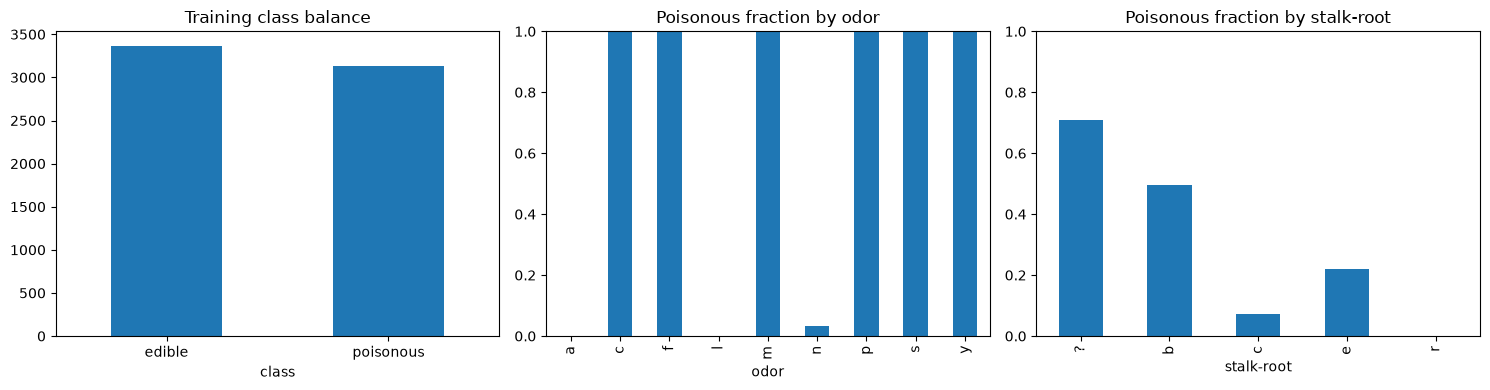

In [3]:
FEATURES = df.columns.drop('class').tolist()
X, y = df[FEATURES], df['class'].eq('p').astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
print('Train:', len(X_train), 'Test:', len(X_test))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
y_train.value_counts().sort_index().rename(index={0:'edible',1:'poisonous'}).plot.bar(ax=axes[0], title='Training class balance', rot=0)
explore = X_train.assign(poisonous=y_train)
for ax, feature in zip(axes[1:], ['odor', 'stalk-root']):
    explore.groupby(feature)['poisonous'].mean().plot.bar(ax=ax, title=f'Poisonous fraction by {feature}', ylim=(0,1))
plt.tight_layout()
plt.show()

## 3. A baseline to beat
Always predict the training majority class. Accuracy alone can hide missed poisonous cases; report poisonous recall, precision, F1 and ROC AUC too.

In [4]:
majority = y_train.mode()[0]
baseline = accuracy_score(y_test, np.full(len(y_test), majority))
print(f'Majority baseline accuracy: {baseline:.4f}')

Majority baseline accuracy: 0.5182


## 4. Encode categories and compare three models
One-hot encoding creates indicator columns without inventing an order between codes. The pipeline fits its encoder inside each training fold. Compare logistic regression, a decision tree, and a random forest using five-fold ROC AUC. The test set is not used to select a model.

In [5]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    'logistic regression': make_pipeline(
        OneHotEncoder(handle_unknown='ignore'),
        LogisticRegression(max_iter=2000, random_state=42),
    ),
    'decision tree': make_pipeline(
        OneHotEncoder(handle_unknown='ignore'),
        DecisionTreeClassifier(random_state=42),
    ),
    'random forest': make_pipeline(
        OneHotEncoder(handle_unknown='ignore'),
        RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=1),
    ),
}
scores = {}
rows = []
for name, candidate in models.items():
    values = cross_val_score(candidate, X_train, y_train, cv=folds, scoring='roc_auc')
    scores[name] = float(values.mean())
    rows.append({'algorithm': name, 'mean_auc': values.mean(), 'std_auc': values.std()})
display(pd.DataFrame(rows))
best_name = max(scores, key=scores.get)
model = models[best_name]
print('Selected:', best_name)

,algorithm,mean_auc,std_auc
0,logistic regression,0.999998,4.739662e-06
1,decision tree,0.999681,6.379585e-04
2,random forest,1.000000,4.965068e-17


Selected: random forest


## 5. Choose a decision threshold on training data
Use out-of-fold probabilities: each training row is predicted by a model that did not fit that row. Maximize poisonous-class F1; choose the threshold nearest 0.5 on ties. This classroom objective balances precision and recall; it does not guarantee zero missed poisonous mushrooms.

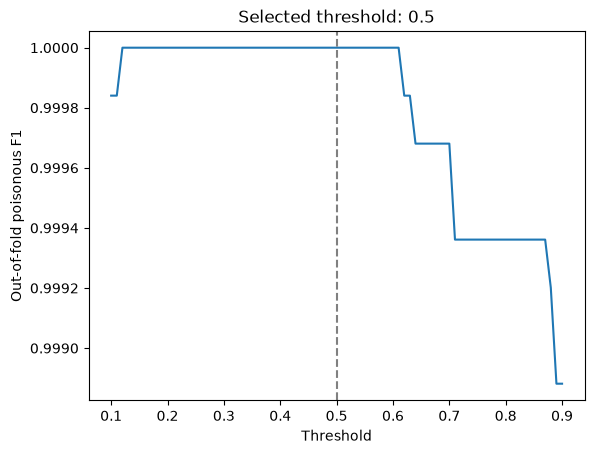

In [6]:
oof = cross_val_predict(model, X_train, y_train, cv=folds, method='predict_proba')[:, 1]
thresholds = np.round(np.arange(.1, .91, .01), 2)
f1s = np.array([f1_score(y_train, oof >= t) for t in thresholds])
tied = thresholds[np.isclose(f1s, f1s.max(), rtol=0, atol=1e-12)]
threshold = float(tied[np.argmin(abs(tied - .5))])
plt.plot(thresholds, f1s)
plt.axvline(threshold, linestyle='--', color='gray')
plt.xlabel('Threshold'); plt.ylabel('Out-of-fold poisonous F1')
plt.title(f'Selected threshold: {threshold}')
plt.show()

## 6. Fit and evaluate once on held-out data
Read the bottom-left confusion cell as missed poisonous cases. High scores on this dataset do not measure reliability on new species or field observations. Probability outputs are model estimates, not calibrated safety guarantees.

accuracy     1.0
precision    1.0
recall       1.0
f1           1.0
roc_auc      1.0
dtype: float64

              precision    recall  f1-score   support

      edible     1.0000    1.0000    1.0000       842
   poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



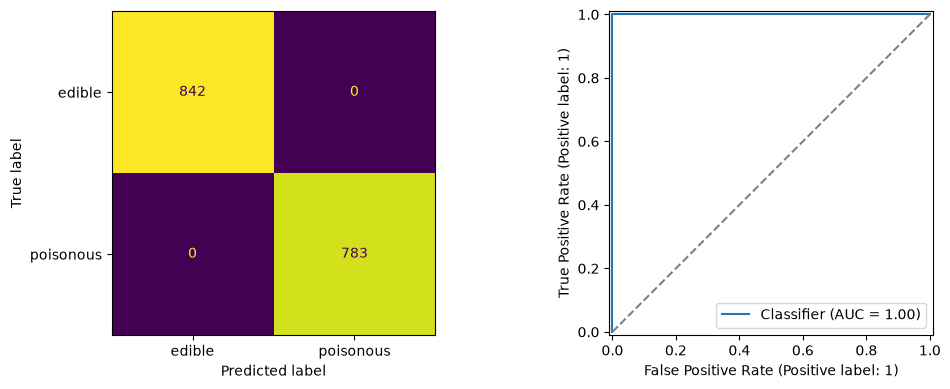

In [7]:
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
predicted = proba >= threshold
metrics = {
    'accuracy': accuracy_score(y_test, predicted),
    'precision': precision_score(y_test, predicted, zero_division=0),
    'recall': recall_score(y_test, predicted, zero_division=0),
    'f1': f1_score(y_test, predicted, zero_division=0),
    'roc_auc': roc_auc_score(y_test, proba),
}
display(pd.Series(metrics))
print(classification_report(y_test, predicted, target_names=['edible','poisonous'], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_test, predicted, display_labels=['edible','poisonous'], ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1])
axes[1].plot([0,1],[0,1], '--', color='gray')
plt.tight_layout(); plt.show()

## 7. Which features matter?
Shuffle each original feature and measure the drop in test ROC AUC. This explains the fitted model; do not use these test results to tune it. Correlated features can share importance.

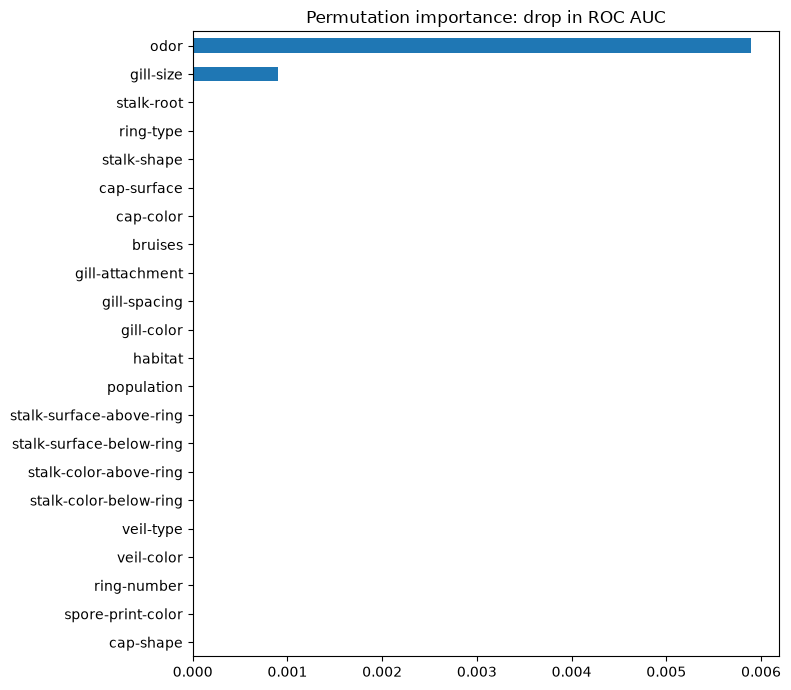

In [8]:
importance = permutation_importance(model, X_test, y_test, scoring='roc_auc', n_repeats=3, random_state=42, n_jobs=1)
pd.Series(importance.importances_mean, index=FEATURES).sort_values().plot.barh(figsize=(8,7), title='Permutation importance: drop in ROC AUC')
plt.tight_layout(); plt.show()

## 8. Predict and inspect errors
Use real held-out feature rows in the same feature order as the API. These are examples from the dataset, not independent field validation.

In [9]:
examples = X_test.head(5)
display(examples.assign(actual=y_test.head(5).map({0:'edible',1:'poisonous'}), poisonous_probability=model.predict_proba(examples)[:,1]))
mistakes = X_test.assign(actual=y_test, predicted=predicted)[y_test != predicted]
print('Errors:', len(mistakes))
display(mistakes.head())

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat,actual,poisonous_probability
4632,x,y,g,f,f,f,c,b,p,e,...,n,p,w,o,l,h,y,d,poisonous,1.0
3444,x,s,w,f,c,f,c,n,u,e,...,w,p,w,o,p,n,s,d,poisonous,1.0
1209,x,f,w,f,n,f,w,b,p,t,...,w,p,w,o,e,n,s,g,edible,0.0
6880,f,s,e,f,f,f,c,n,b,t,...,w,p,w,o,e,w,v,p,poisonous,1.0
4542,x,f,y,f,f,f,c,b,g,e,...,n,p,w,o,l,h,y,g,poisonous,1.0


Errors: 0


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat,actual,predicted


## 9. Save the pipeline and metadata for FastAPI
Save the encoder with the classifier, feature order, threshold, held-out metrics, CV scores and library version. The API loads this bundle once at startup. Only load trusted joblib files.

In [10]:
bundle = {
    'model': model,
    'algorithm': best_name,
    'features': FEATURES,
    'threshold': threshold,
    'metrics': metrics,
    'cv_scores': scores,
    'baseline_accuracy': float(baseline),
    'labels': {'e': 'edible', 'p': 'poisonous'},
    'trained_at': pd.Timestamp.now(tz='UTC').isoformat(timespec='seconds'),
    'sklearn_version': sklearn.__version__,
}
Path('../models').mkdir(exist_ok=True)
joblib.dump(bundle, '../models/mushroom.joblib')
print('Saved: ../models/mushroom.joblib')

Saved: ../models/mushroom.joblib
